# 02 · Control de calidad de las 10 señales

**Capítulo 1 — Etapa 2 del pipeline · Bloques B (calidad) y C (rangos) del EDA**

## ¿Qué hace este notebook?
Busca, muestra por muestra, problemas que indican que **el sensor no estaba midiendo bien**. En esta etapa
**solo se detecta**: la señal no se modifica. Cada problema queda en una "máscara" (una lista de verdadero/falso del
mismo largo que la señal).

## Los criterios y por qué
| Criterio | Qué significa | Ejemplo en WESAD | Nivel |
|---|---|---|---|
| `nan` | dato faltante | — | excluir |
| `fuera_de_rango` | valor que el cuerpo no puede producir | temperatura de −273 °C (sensor desconectado) | excluir |
| `saturacion` | la señal pegada al tope del sensor ≥ 0.1 s | ECG clavado en ±1.5 mV | excluir (muñeca ACC: marcar) |
| `saturacion_breve` | toques muy cortos del tope | la punta de una onda R grande recortada | marcar |
| `plana` | señal casi sin variación por varios segundos | electrodo despegado | excluir |
| `pegada` | el mismo valor exacto repetido por ≥ 60 s | sensor congelado (EDA, temperatura) | excluir |
| `salto` | cambio más rápido de lo fisiológico (EDA > 10 µS/s) | electrodo que se mueve | excluir (±5 s) |

Los umbrales de EDA vienen de **Kleckner et al. (2018)**; los demás son límites físicos de cada sensor.
Todos los números están en `wesad_pre/config.py` (diccionario `QC`).

**Por qué antes de dividir en entrenamiento/prueba:** el criterio debe ser idéntico para todos los sujetos;
si no, el desempeño del modelo dejaría de ser comparable.

**"Excluir" no es "borrar".** Las muestras excluidas se ignoran al calcular eventos y ventanas; una ventana solo se
descarta para una modalidad si menos del 80 % de sus muestras son válidas (notebook 05).

In [1]:
import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from wesad_pre import config as cfg
from wesad_pre import carga, etiquetas, calidad, limpieza, eventos, procesamiento, marcadores, estadistica, ventanas
from wesad_pre import graficas as gr

warnings.filterwarnings("ignore")
gr.setup()
pd.set_option("display.max_columns", 50, "display.width", 200)

DATA_PATH = os.path.join("..", "WESAD")   # carpeta con S2/, S3/, ... (ajústala si los datos están en otro lugar)
SUBJECTS = cfg.SUBJECT_IDS
os.makedirs(cfg.OUT_DIRS["tables"], exist_ok=True)

### Los umbrales configurados

In [2]:
pd.DataFrame({k: {c: v for c, v in d.items()} for k, d in cfg.QC.items()}).T

,range,rail,rail_breve,flat_std,flat_equal_s,slope
chest_ECG,"(-5.0, 5.0)","{'value': 1.49, 'min_s': 0.1, 'level': 'excluir'}","{'value': 1.49, 'level': 'marcar'}","{'value': 0.005, 'min_s': 2.0, 'level': 'exclu...",NaN,NaN
chest_EMG,"(-5.0, 5.0)","{'value': 1.49, 'min_s': 0.1, 'level': 'excluir'}","{'value': 1.49, 'level': 'marcar'}","{'value': 0.0005, 'min_s': 2.0, 'level': 'excl...",NaN,NaN
chest_EDA,"(0.05, 60.0)",NaN,NaN,NaN,"{'value': 60.0, 'level': 'excluir'}","{'value': 10.0, 'pad_s': 5.0, 'level': 'excluir'}"
wrist_EDA,"(0.05, 60.0)",NaN,NaN,NaN,"{'value': 60.0, 'level': 'excluir'}","{'value': 10.0, 'pad_s': 5.0, 'level': 'excluir'}"
chest_Resp,"(-60.0, 60.0)","{'value': 49.9, 'min_s': 0.5, 'level': 'excluir'}",NaN,"{'value': 0.05, 'min_s': 10.0, 'level': 'exclu...",NaN,NaN
chest_Temp,"(20.0, 42.0)",NaN,NaN,NaN,"{'value': 60.0, 'level': 'excluir'}",NaN
wrist_TEMP,"(20.0, 42.0)",NaN,NaN,NaN,"{'value': 60.0, 'level': 'excluir'}",NaN
wrist_BVP,NaN,NaN,NaN,"{'value': 0.01, 'min_s': 2.0, 'level': 'excluir'}",NaN,NaN
chest_ACC,"(-8.0, 8.0)",NaN,NaN,NaN,NaN,NaN
wrist_ACC,"(-8.0, 8.0)","{'value': 1.98, 'min_s': 0.0, 'level': 'marcar'}",NaN,NaN,NaN,NaN


## 1. Aplicar el QC a los 15 sujetos
Se procesa un sujeto a la vez (cada `.pkl` pesa cerca de 1 GB) y se guardan las máscaras en `salidas/qc/`
para que los notebooks siguientes no tengan que recalcularlas. Tarda unos minutos.

In [3]:
resumen, tramos = [], []
for sid in SUBJECTS:
    data = carga.load_subject(DATA_PATH, sid)
    r, t = procesamiento.qc_subject(data, sid)
    resumen += r; tramos += t
    del data; _ = gc.collect()
    print(f"S{sid} listo", end=" · ")

resumen = pd.DataFrame(resumen).fillna(0)
tramos = pd.DataFrame(tramos)
resumen.to_csv(os.path.join(cfg.OUT_DIRS["tables"], "qc_resumen.csv"), index=False)
tramos.to_csv(os.path.join(cfg.OUT_DIRS["tables"], "qc_tramos.csv"), index=False)
print(f"\n{len(tramos)} tramos marcados en total")

S2 listo · 

S3 listo · 

S4 listo · 

S5 listo · 

S6 listo · 

...

S14 listo · 

S15 listo · 

S16 listo · 

S17 listo · 


40752 tramos marcados en total


## 2. Panorama: ¿qué porcentaje de cada señal se excluye?
**Cómo leer el mapa de calor:** cada celda es un sujeto (fila) y una señal (columna); el número es el % de muestras
excluidas. Celdas blancas = señal limpia. Una celda oscura indica un problema concentrado en ese sujeto y ese sensor.

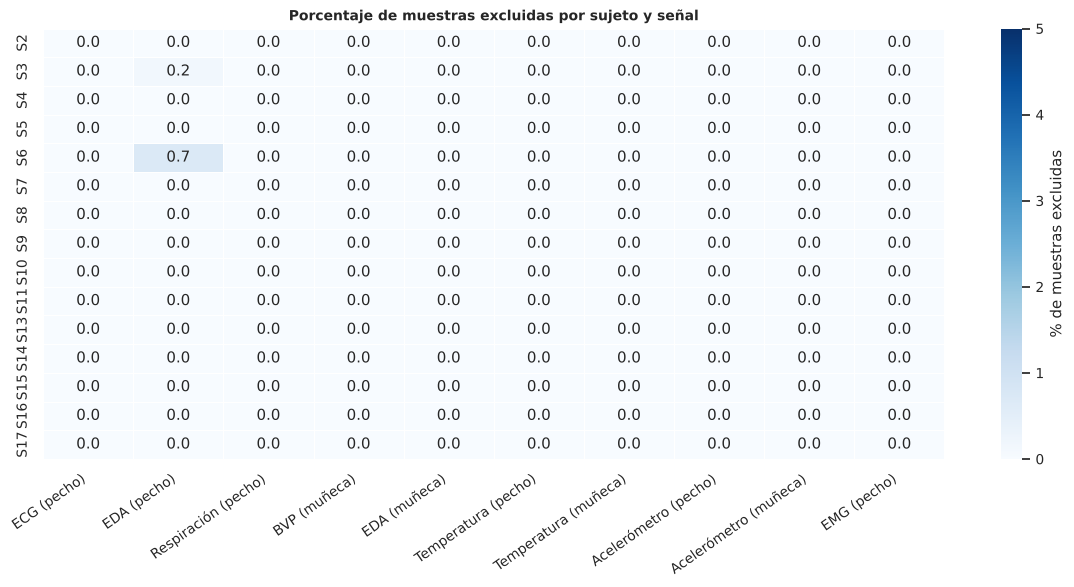

In [4]:
heat = resumen.pivot(index="sujeto", columns="señal", values="pct_excluido")
heat = heat.loc[sorted(heat.index, key=gr.subject_sort_key), cfg.ALL_SIGNALS]
heat.columns = [cfg.SIGNALS[k]["name"] for k in heat.columns]
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=max(5, heat.values.max()),
            cbar_kws={"label": "% de muestras excluidas"}, linewidths=0.5, linecolor="white", ax=ax)
ax.set_title("Porcentaje de muestras excluidas por sujeto y señal"); ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=35, ha="right"); fig.tight_layout(); gr.savefig(fig, "02_qc_mapa_calor"); plt.show()

**¿Qué criterio explica las exclusiones?** Promedio entre sujetos del % de muestras afectadas por cada criterio:

In [5]:
crit = [c for c in resumen.columns if c.startswith("pct_") and c not in ("pct_excluido", "pct_marcado")]
por_criterio = resumen.groupby("señal")[crit + ["pct_excluido", "pct_marcado"]].mean().loc[cfg.ALL_SIGNALS]
por_criterio.round(3)

,pct_nan,pct_fuera_de_rango,pct_saturacion,pct_saturacion_breve,pct_plana,pct_pegada,pct_salto,pct_excluido,pct_marcado
señal,,,,,,,,,
chest_ECG,0.0,0.0,0.000,0.507,0.0,0.0,0.000,0.000,0.507
chest_EDA,0.0,0.0,0.000,0.000,0.0,0.0,0.059,0.059,0.000
chest_Resp,0.0,0.0,0.000,0.000,0.0,0.0,0.000,0.000,0.000
wrist_BVP,0.0,0.0,0.000,0.000,0.0,0.0,0.000,0.000,0.000
wrist_EDA,0.0,0.0,0.000,0.000,0.0,0.0,0.000,0.000,0.000
chest_Temp,0.0,0.0,0.000,0.000,0.0,0.0,0.000,0.000,0.000
wrist_TEMP,0.0,0.0,0.000,0.000,0.0,0.0,0.000,0.000,0.000
chest_ACC,0.0,0.0,0.000,0.000,0.0,0.0,0.000,0.000,0.000
wrist_ACC,0.0,0.0,0.023,0.000,0.0,0.0,0.000,0.000,0.023


## 3. Revisión visual de los casos con más exclusión
Un umbral automático puede equivocarse. Aquí graficamos los **tres casos sujeto-señal con más exclusión**
sombreando en rojo lo excluido y en amarillo lo marcado, para confirmar a ojo que de verdad es un problema
del sensor y no fisiología real.

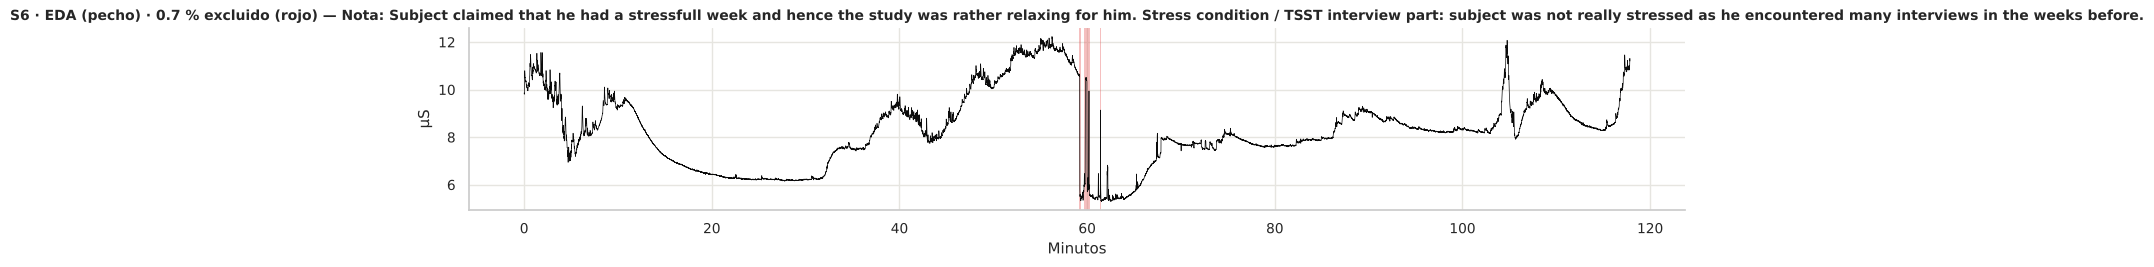

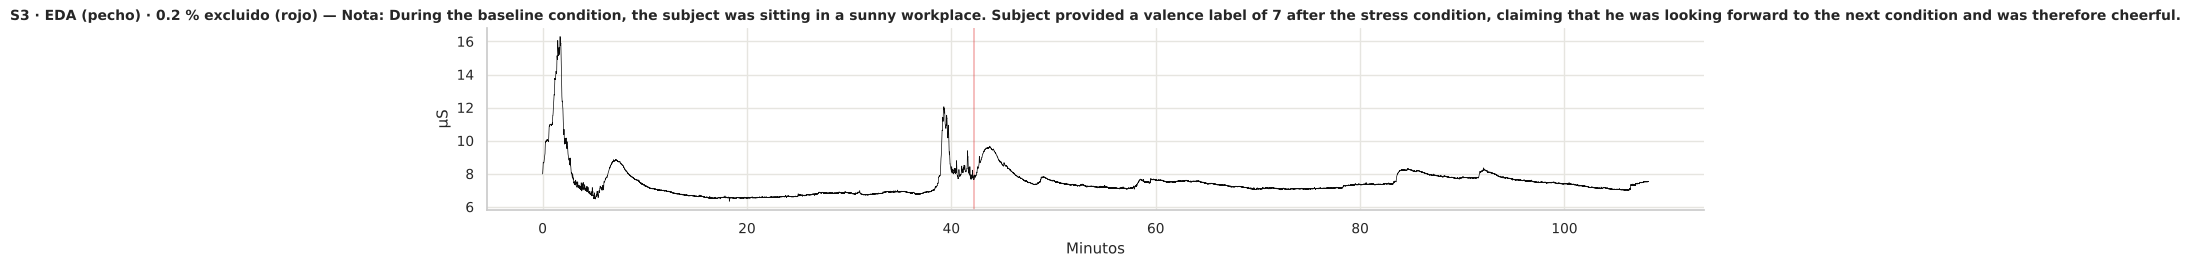

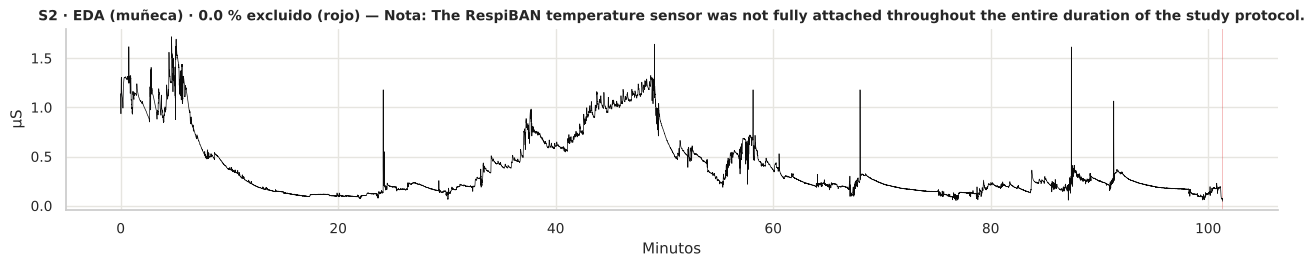

In [6]:
peores = resumen[resumen.pct_excluido > 0].sort_values("pct_excluido", ascending=False).head(3)
for _, r in peores.iterrows():
    sid = int(r.sujeto[1:]); key = r.señal; fs = cfg.SIGNALS[key]["fs"]
    data = carga.load_subject(DATA_PATH, sid)
    x = carga.magnitude(carga.get_signal(data, key)); b = etiquetas.condition_blocks(data["label"])
    qc = procesamiento.load_qc(sid)[key]
    step = max(fs // 4, 1); t = np.arange(0, len(x), step) / fs / 60
    fig, ax = plt.subplots(figsize=(13, 2.8))
    ax.plot(t, x[::step], color="#0b0b0b", lw=0.5)
    for lvl, col in (("excluir", "#e34948"), ("marcar", "#eda100")):
        for s, e in etiquetas.find_blocks(qc[lvl]):
            ax.axvspan(s / fs / 60, e / fs / 60, color=col, alpha=0.35, lw=0)
    nota = carga.read_notes(DATA_PATH, sid)
    ax.set_title(f"{r.sujeto} · {cfg.SIGNALS[key]['name']} · {r.pct_excluido:.1f} % excluido (rojo)" + (f" — Nota: {nota}" if nota else ""))
    ax.set_xlabel("Minutos"); ax.set_ylabel(cfg.SIGNALS[key]["unit"])
    fig.tight_layout(); gr.savefig(fig, f"02_caso_{r.sujeto}_{key}"); plt.show()
    del data; _ = gc.collect()
if peores.empty:
    print("Ningún sujeto tiene muestras excluidas.")

## 4. ¿Los umbrales tienen sentido? Rango real de cada señal
Comparamos el rango observado (percentiles 0.1 y 99.9 de cada sujeto) contra los límites configurados.
Si el percentil 99.9 de muchos sujetos tocara el límite, el umbral sería demasiado estricto.

In [7]:
rng_rows = []
for sid in SUBJECTS:
    data = carga.load_subject(DATA_PATH, sid)
    for key in cfg.ALL_SIGNALS:
        x = carga.get_signal(data, key)
        x = x.ravel() if x.ndim == 1 else x.ravel()
        p = np.nanpercentile(x, [0, 0.1, 50, 99.9, 100])
        rng_rows.append(dict(sujeto=f"S{sid}", señal=key, min=p[0], p0_1=p[1], mediana=p[2], p99_9=p[3], max=p[4]))
    del data; _ = gc.collect()
rangos = pd.DataFrame(rng_rows)
lims = {k: v.get("range", (np.nan, np.nan)) for k, v in cfg.QC.items()}
tabla_rangos = rangos.groupby("señal").agg(min_global=("min", "min"), p0_1_mediana=("p0_1", "median"),
                                           mediana=("mediana", "median"), p99_9_mediana=("p99_9", "median"),
                                           max_global=("max", "max")).loc[cfg.ALL_SIGNALS]
tabla_rangos["limite_inferior"] = [lims.get(k, (np.nan,))[0] for k in tabla_rangos.index]
tabla_rangos["limite_superior"] = [lims.get(k, (np.nan, np.nan))[1] for k in tabla_rangos.index]
tabla_rangos["unidad"] = [cfg.SIGNALS[k]["unit"] for k in tabla_rangos.index]
tabla_rangos.to_csv(os.path.join(cfg.OUT_DIRS["tables"], "qc_rangos.csv"))
tabla_rangos.round(3)

,min_global,p0_1_mediana,mediana,p99_9_mediana,max_global,limite_inferior,limite_superior,unidad
señal,,,,,,,,
chest_ECG,-1.500,-0.632,-0.028,1.499,1.500,-5.00,5.0,mV
chest_EDA,0.000,2.751,3.026,6.340,22.411,0.05,60.0,µS
chest_Resp,-50.000,-18.465,-0.221,19.894,38.800,-60.00,60.0,%
wrist_BVP,-1773.760,-392.922,2.530,314.380,1789.000,NaN,NaN,u.a.
wrist_EDA,0.045,0.255,0.472,2.997,15.921,0.05,60.0,µS
chest_Temp,-273.150,33.080,34.129,34.815,35.778,20.00,42.0,°C
wrist_TEMP,28.970,30.990,32.660,34.290,35.970,20.00,42.0,°C
chest_ACC,-6.600,-0.678,-0.002,0.983,4.508,-8.00,8.0,g
wrist_ACC,-2.000,-1.031,0.250,1.156,1.984,-8.00,8.0,g


## 📌 Qué encontramos con los datos reales
- **Los `.pkl` de WESAD están muy limpios de fallas groseras:** en ningún sujeto ni señal se excluye más del 1 %.
  El caso mayor es S6 en la EDA de pecho (0.72 %, por saltos de más de 10 µS/s).
- El valor imposible de **−273.15 °C** (sensor de temperatura desconectado) aparece solo un instante en S3.
- **El ECG toca el tope del sensor (±1.5 mV) en pulsos muy breves**: son las puntas de ondas R grandes, recortadas.
  Afecta hasta el 2.3 % de las muestras (S16) y por eso se **marcan** pero no se excluyen: la posición del pico R
  sigue siendo detectable.
- El acelerómetro de muñeca toca su límite (±2 g) en menos del 0.1 % de las muestras (se marca, no se excluye).
- **Conclusión:** el problema de calidad de WESAD no son los sensores desconectados sino los **artefactos de
  movimiento**, que no se ven en el QC por muestra. Por eso el notebook 03 mide la calidad fisiológica
  (latidos que coinciden, segmentos de ECG aceptables) y el movimiento.

## Resumen de este notebook
- Máscaras guardadas en `salidas/qc/S{id}_qc.npz`; resumen y tramos en `salidas/tablas/qc_*.csv`
  (sirven como anexo del capítulo).
- Siguiente paso: **03_limpieza_y_eventos**.